# 01 — Exploration des données EnerVision

## Objectif

Ce notebook vise à analyser les données énergétiques collectées depuis l'API EnerVision afin d'évaluer leur qualité et leur pertinence pour les futurs modèles de Machine Learning.

L'analyse portera sur la structure du dataset, les distributions, les valeurs manquantes, la cohérence temporelle et les éventuelles anomalies physiques.

**Attention :** les précédents tests ont révélé que l'API pouvait générer des valeurs différentes pour une même période. Les résultats de cette exploration doivent donc être interprétés comme ceux de données synthétiques.

A - Chargement des fichiers JSON
- Attendu : 7 sites pour 1000 mesures / site

In [2]:
from pathlib import Path
import json
import pandas as pd

# Notre notebook se trouve dans ml/notebooks/
RAW_DIR = Path("../data/raw")

records = []

files = sorted(RAW_DIR.glob("*.json"))

print(f"Fichiers trouvés : {len(files)}")

for file in files:
    with file.open(encoding="utf-8") as f:
        payload = json.load(f)

    for reading in payload["readings"]:
        records.append({
            **reading,
            "collected_at": payload["collected_at"],
            "source_file": file.name,
        })

if not records:
    raise ValueError("Aucune mesure trouvée dans data/raw")

df = pd.DataFrame(records)

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["collected_at"] = pd.to_datetime(df["collected_at"], utc=True)

print(f"Nombre de mesures : {len(df)}")
print(f"Nombre de sites : {df['site_id'].nunique()}")

display(df.head())

Fichiers trouvés : 7
Nombre de mesures : 7000
Nombre de sites : 7


,timestamp,site_id,site_type,consumption_kw,consumption_kwh,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent,null_reasons,data_quality,collected_at,source_file
0,2026-10-20 08:13:41.391918+00:00,SITE001,office,81.41,81.41,404.1,122.43,0.908,9.3,46.7,[],good,2026-10-21 08:18:41.391918+00:00,SITE001_20261021_081841.json
1,2026-10-20 08:15:07.791918+00:00,SITE001,office,84.19,84.19,400.7,127.70,0.910,7.4,46.2,[],good,2026-10-21 08:18:41.391918+00:00,SITE001_20261021_081841.json
2,2026-10-20 08:16:34.191918+00:00,SITE001,office,87.00,87.00,405.7,130.33,0.852,NaN,46.8,[temperature_sensor_failure],partial,2026-10-21 08:18:41.391918+00:00,SITE001_20261021_081841.json
3,2026-10-20 08:18:00.591918+00:00,SITE001,office,82.19,82.19,397.3,125.71,0.942,11.4,46.2,[],good,2026-10-21 08:18:41.391918+00:00,SITE001_20261021_081841.json
4,2026-10-20 08:19:26.991918+00:00,SITE001,office,86.72,86.72,406.7,129.61,0.963,8.7,43.7,[],good,2026-10-21 08:18:41.391918+00:00,SITE001_20261021_081841.json


B - Structure du Dataset
 - Vérifier que les mesures ont été correctement chargées et que les variables numériques sont exploitables

In [3]:
print("Dimensions :", df.shape)

print("\nTypes des colonnes :")
display(df.dtypes.to_frame("Type"))

print("\nMesures par site :")
display(
    df.groupby(["site_id", "site_type"])
    .size()
    .rename("Nombre de mesures")
    .to_frame()
)

print("\nStatistiques descriptives :")
display(df.describe().T)

Dimensions : (7000, 14)

Types des colonnes :


,Type
timestamp,"datetime64[us, UTC]"
site_id,str
site_type,str
consumption_kw,float64
consumption_kwh,float64
voltage_v,float64
current_a,float64
power_factor,float64
temperature_celsius,float64
humidity_percent,float64



Mesures par site :


,,Nombre de mesures
site_id,site_type,
SITE001,office,1000
SITE002,factory,1000
SITE003,datacenter,1000
SITE004,retail,1000
SITE005,hospital,1000
SITE006,office,1000
SITE007,factory,1000



Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
consumption_kw,6591.0,417.839220,303.114339,46.77,131.235,344.880,724.830,1042.53
consumption_kwh,6591.0,417.839220,303.114339,46.77,131.235,344.880,724.830,1042.53
voltage_v,6602.0,400.027083,5.013780,379.50,396.700,400.000,403.475,419.70
current_a,6602.0,635.809532,460.333367,71.18,200.470,526.620,1101.940,1606.77
power_factor,6602.0,0.920195,0.029450,0.85,0.900,0.921,0.941,0.98
temperature_celsius,6354.0,5.034671,4.067759,-5.70,1.800,5.100,8.300,16.40
humidity_percent,6440.0,42.748556,5.021730,30.00,39.300,42.800,46.200,61.80


## 2 — Analyse de la qualité des données

Cette section vise à identifier les valeurs manquantes, à examiner les indicateurs de qualité fournis par l'API et à détecter les éventuelles incohérences entre variables.

L'objectif est de déterminer les traitements nécessaires avant toute phase de modélisation.

A - Analyse des valeurs manquantes

In [4]:
missing = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "Pourcentage (%)": (df.isna().mean() * 100).round(2),
})

display(
    missing.sort_values(
        "Pourcentage (%)",
        ascending=False
    )
)

,Valeurs manquantes,Pourcentage (%)
temperature_celsius,646,9.23
humidity_percent,560,8.00
consumption_kwh,409,5.84
consumption_kw,409,5.84
voltage_v,398,5.69
power_factor,398,5.69
current_a,398,5.69
site_type,0,0.00
timestamp,0,0.00
site_id,0,0.00


B - Qualité déclarée par l'API
 - Vérification et count de data_quality au global
 - Répartition par site en pourcentage

In [5]:
print("Répartition de data_quality :")

display(
    df["data_quality"]
    .value_counts(dropna=False)
    .to_frame("Nombre de mesures")
)

print("\nRépartition par site :")

display(
    pd.crosstab(
        df["site_id"],
        df["data_quality"],
        normalize="index"
    ).mul(100).round(2)
)

Répartition de data_quality :


,Nombre de mesures
data_quality,
good,5514
partial,1228
critical,131
degraded,127



Répartition par site :


data_quality,critical,degraded,good,partial
site_id,,,,
SITE001,2.5,1.2,77.7,18.6
SITE002,1.9,1.6,80.1,16.4
SITE003,1.4,1.3,80.3,17.0
SITE004,2.0,1.9,78.5,17.6
SITE005,1.5,1.8,79.8,16.9
SITE006,1.8,2.4,77.9,17.9
SITE007,2.0,2.5,77.1,18.4


C - Vérification de kW et kWh
 - Les données kW et kWh semblent systématiquement correspondre. Etude de ce cas de figure

In [6]:
valid = df[
    ["consumption_kw", "consumption_kwh"]
].dropna()

identical = (
    valid["consumption_kw"]
    == valid["consumption_kwh"]
)

print(f"Mesures comparables : {len(valid)}")
print(f"Valeurs identiques : {identical.sum()}")
print(f"Pourcentage identique : {identical.mean() * 100:.2f}%")

Mesures comparables : 6591
Valeurs identiques : 6591
Pourcentage identique : 100.00%


## 3 — Analyse des valeurs manquantes et des indicateurs de qualité

Les valeurs manquantes ne sont pas systématiquement considérées comme des anomalies à supprimer.

L'API EnerVision fournit deux métadonnées complémentaires :

- `data_quality` : niveau de qualité déclaré pour chaque mesure.
- `null_reasons` : informations relatives aux causes d'absence de certaines valeurs.

Cette analyse vise à déterminer si les valeurs manquantes sont cohérentes avec ces indicateurs, afin d'orienter les futurs choix de prétraitement.

A - Valeurs manquantes selon la qualité
 - Examen du nombre de valeurs manquantes pour chaque catégorie de qualité

In [7]:
measure_columns = [
    "consumption_kw",
    "consumption_kwh",
    "voltage_v",
    "current_a",
    "power_factor",
    "temperature_celsius",
    "humidity_percent",
]

df["missing_count"] = df[measure_columns].isna().sum(axis=1)

display(
    df.groupby("data_quality")["missing_count"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

,count,mean,min,max
data_quality,,,,
critical,131,7.00,7,7
degraded,127,3.37,2,6
good,5514,0.00,0,0
partial,1228,1.53,1,3


B - Explorer les null_reasons

In [8]:
print("Exemples de null_reasons :")

display(
    df.loc[
        df["missing_count"] > 0,
        ["site_id", "data_quality", "missing_count", "null_reasons"]
    ].head(15)
)

print("\nTypes de données présents :")

display(
    df["null_reasons"]
    .map(lambda x: type(x).__name__)
    .value_counts()
)

Exemples de null_reasons :


,site_id,data_quality,missing_count,null_reasons
2,SITE001,partial,1,[temperature_sensor_failure]
5,SITE001,partial,2,[consumption_sensor_failure]
8,SITE001,partial,1,[temperature_sensor_failure]
9,SITE001,degraded,2,"[temperature_sensor_failure, humidity_sensor_f..."
11,SITE001,partial,1,[humidity_sensor_failure]
25,SITE001,partial,1,[humidity_sensor_failure]
28,SITE001,partial,1,[humidity_sensor_failure]
30,SITE001,partial,1,[temperature_sensor_failure]
40,SITE001,critical,7,[network_loss]
45,SITE001,partial,1,[humidity_sensor_failure]



Types de données présents :


null_reasons
list    7000
Name: count, dtype: int64

C - Vérifier la cohérence des indicateurs : 
- Est ce que des mesures "good" contiennent des valeurs manquantes?

In [9]:
df["has_missing"] = df["missing_count"] > 0

display(
    pd.crosstab(
        df["data_quality"],
        df["has_missing"],
        margins=True
    )
)

has_missing,False,True,All
data_quality,,,
critical,0,131,131
degraded,0,127,127
good,5514,0,5514
partial,0,1228,1228
All,5514,1486,7000


D - Détail du nombre de null_reasons

In [11]:
from collections import Counter

reason_counts = Counter(
    reason
    for reasons in df["null_reasons"]
    for reason in reasons
)

display(
    pd.DataFrame(
        reason_counts.items(),
        columns=["Raison", "Occurrences"]
    ).sort_values("Occurrences", ascending=False)
)

,Raison,Occurrences
0,temperature_sensor_failure,515
2,humidity_sensor_failure,429
1,consumption_sensor_failure,278
4,electrical_sensor_failure,267
3,network_loss,131


E - Variables manquantes selon la qualité

In [12]:
missing_by_quality = (
    df.groupby("data_quality")[measure_columns]
    .apply(lambda group: group.isna().mean() * 100)
    .round(2)
)

display(missing_by_quality)

,consumption_kw,consumption_kwh,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent
data_quality,,,,,,,
critical,100.00,100.00,100.00,100.00,100.00,100.00,100.00
degraded,41.73,41.73,44.88,44.88,44.88,63.78,55.12
good,0.00,0.00,0.00,0.00,0.00,0.00,0.00
partial,18.32,18.32,17.10,17.10,17.10,35.34,29.23


### Conclusion — Gestion des valeurs manquantes

L'analyse des 7 000 mesures met en évidence une relation systématique entre les valeurs manquantes et les indicateurs de qualité fournis par l'API EnerVision.

Les observations classées `good` ne présentent aucune valeur manquante, tandis que les observations `partial`, `degraded` et `critical` présentent des niveaux croissants d'indisponibilité.

Les informations contenues dans `null_reasons` permettent également d'identifier différentes causes potentielles, notamment les défaillances de capteurs et les pertes de communication.

**Décision retenue :** aucune suppression systématique des observations contenant des valeurs manquantes ne sera effectuée à ce stade.

Les données brutes seront conservées intégralement. Les stratégies d'exclusion ou d'imputation seront définies ultérieurement en fonction des besoins spécifiques des modèles de Machine Learning.

Cette approche permet de préserver les informations relatives à la qualité des mesures et d'envisager leur exploitation pour des fonctionnalités de surveillance ou de détection d'anomalies.

## 4 — Analyse comparative des sites

### Objectif

Cette analyse vise à identifier les différences de comportement énergétique entre les sites et les catégories de bâtiments.

Elle doit contribuer au choix de la stratégie de modélisation :

- Un modèle global commun à l'ensemble des sites.
- Un modèle spécialisé par catégorie de bâtiment.
- Un modèle individualisé pour chaque site.

Les premières comparaisons porteront sur les distributions de consommation, leur variabilité et les éventuelles différences entre sites d'une même catégorie.

Ces observations seront ensuite complétées par une analyse temporelle et par des expérimentations comparatives des modèles.

A - Statistiques énergétiques par site. Le coefficient de variation (cv_percent) permet de comparer la variabilité relative des consommations, même lorsque des sites ont des puissances très différentes

In [13]:
site_stats = (
    df.groupby(["site_id", "site_type"])
    .agg(
        observations=("consumption_kw", "count"),
        mean_kw=("consumption_kw", "mean"),
        median_kw=("consumption_kw", "median"),
        std_kw=("consumption_kw", "std"),
        min_kw=("consumption_kw", "min"),
        max_kw=("consumption_kw", "max"),
    )
    .round(2)
)

site_stats["cv_percent"] = (
    site_stats["std_kw"] / site_stats["mean_kw"] * 100
).round(2)

display(site_stats)

,,observations,mean_kw,median_kw,std_kw,min_kw,max_kw,cv_percent
site_id,site_type,,,,,,,
SITE001,office,934,104.04,66.12,50.09,49.90,190.51,48.14
SITE002,factory,943,662.93,857.20,300.77,235.19,1042.53,45.37
SITE003,datacenter,954,739.97,738.82,39.85,626.59,868.61,5.39
SITE004,retail,940,218.07,149.79,102.01,106.18,394.83,46.78
SITE005,hospital,940,480.81,480.40,27.57,402.52,579.54,5.73
SITE006,office,941,91.71,59.68,42.70,46.77,171.55,46.56
SITE007,factory,939,620.31,805.16,286.11,219.31,976.96,46.12


B - Consommation moyenne par site

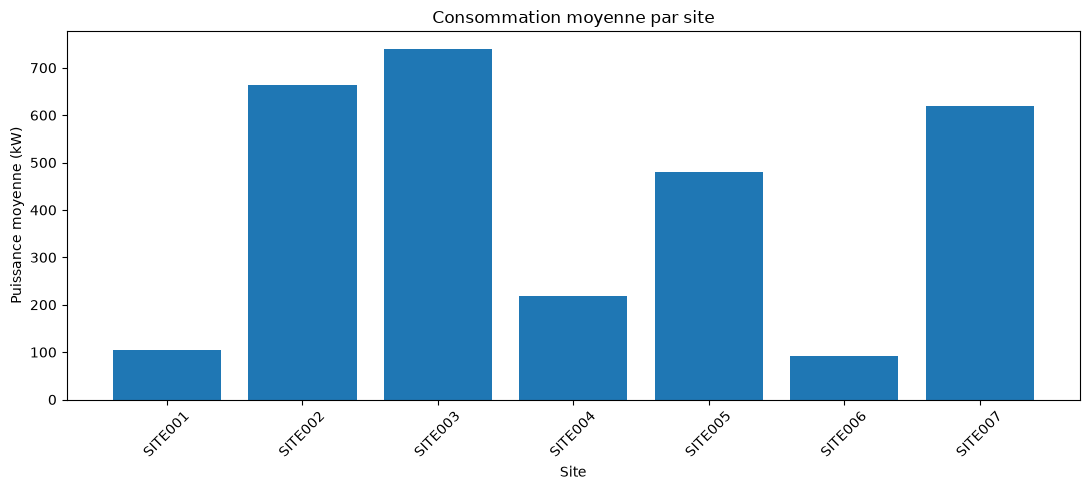

In [14]:
import matplotlib.pyplot as plt

site_stats_reset = site_stats.reset_index()

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    site_stats_reset["site_id"],
    site_stats_reset["mean_kw"],
)

ax.set_title("Consommation moyenne par site")
ax.set_xlabel("Site")
ax.set_ylabel("Puissance moyenne (kW)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C - Comparaison des distributions

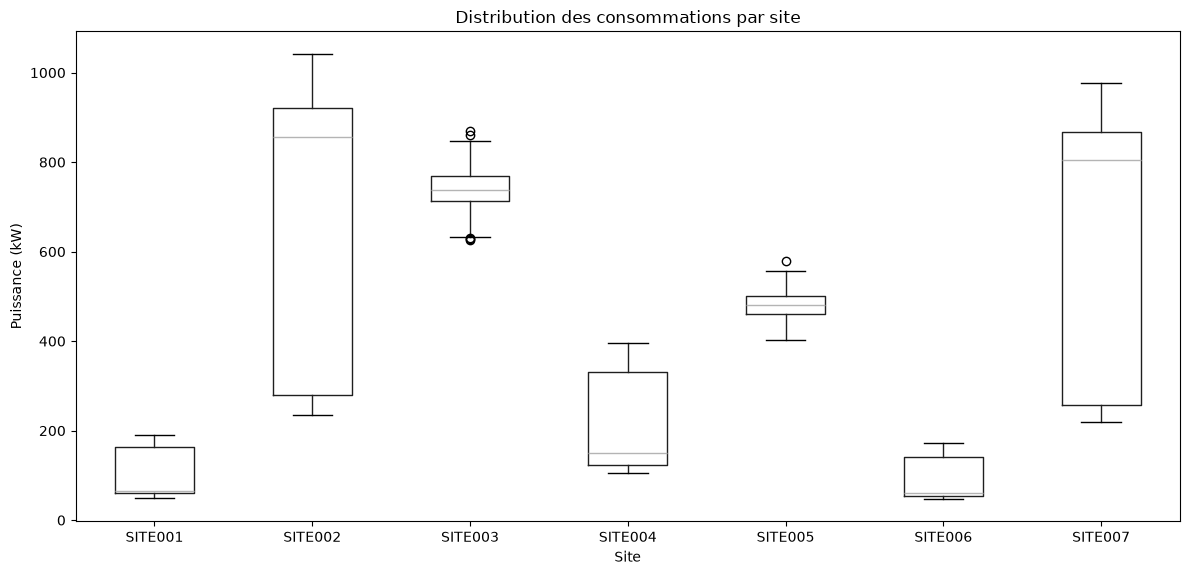

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

df.boxplot(
    column="consumption_kw",
    by="site_id",
    ax=ax,
    grid=False,
)

ax.set_title("Distribution des consommations par site")
ax.set_xlabel("Site")
ax.set_ylabel("Puissance (kW)")

plt.suptitle("")
plt.tight_layout()
plt.show()

D - Comparaison des sites d'un même type (Pour "office" et "factory")

In [16]:
for site_type in ["office", "factory"]:
    subset = df[df["site_type"] == site_type]

    print(f"\nType : {site_type}")

    display(
        subset.groupby("site_id")["consumption_kw"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )


Type : office


,count,mean,median,std,min,max
site_id,,,,,,
SITE001,934,104.04,66.12,50.09,49.90,190.51
SITE006,941,91.71,59.68,42.70,46.77,171.55



Type : factory


,count,mean,median,std,min,max
site_id,,,,,,
SITE002,943,662.93,857.20,300.77,235.19,1042.53
SITE007,939,620.31,805.16,286.11,219.31,976.96


### Conclusion — Comparaison des sites et stratégie de modélisation

L'analyse comparative des sept sites met en évidence des différences importantes de consommation énergétique selon les catégories de sites.

Les bureaux et les usines présentent des consommations moyennes relativement proches au sein de leur catégorie, ainsi que des coefficients de variation comparables.

À l'inverse, les profils du datacenter et de l'hôpital se distinguent par une consommation relativement stable, avec un coefficient de variation inférieur à 6 %, contre environ 45 à 48 % pour les autres sites.

Ces résultats suggèrent que le type de site constitue une variable potentiellement déterminante pour la modélisation énergétique.

Toutefois, les données provenant d'une API de simulation, ces différences peuvent également résulter de règles de génération spécifiques aux catégories de sites.

**Hypothèse retenue :** comparer expérimentalement trois approches de modélisation : globale, par catégorie de site et par site.

Le choix définitif reposera sur les performances prédictives, la capacité de généralisation et les contraintes de maintenance des modèles.

## 5 — Analyse temporelle des consommations

### Objectifs

Cette section vise à étudier la dimension temporelle des mesures énergétiques collectées depuis l'API EnerVision.

L'analyse portera sur :

- La couverture temporelle et la régularité des mesures.
- L'évolution de la consommation électrique sur une période de 24 heures.
- L'identification de cycles de consommation selon les sites et leurs catégories.
- La recherche de comportements temporels potentiellement exploitables pour la prédiction.

**Point de vigilance :** les précédentes expérimentations ont montré que les données historiques de l'API pouvaient être régénérées à chaque requête. La régularité des timestamps ne garantit donc pas l'existence d'un historique réel et stable.

A - Vérification de la couverture temporelle
 - Résultat attendu : Les sept sites doivent couvrir la même période (environ 24h)

In [17]:
temporal_coverage = (
    df.groupby("site_id")
    .agg(
        first_measure=("timestamp", "min"),
        last_measure=("timestamp", "max"),
        observations=("timestamp", "count"),
    )
)

temporal_coverage["duration_hours"] = (
    temporal_coverage["last_measure"]
    - temporal_coverage["first_measure"]
).dt.total_seconds() / 3600

display(temporal_coverage)

,first_measure,last_measure,observations,duration_hours
site_id,,,,
SITE001,2026-10-20 08:13:41.391918+00:00,2026-10-21 08:12:14.991918+00:00,1000,23.976
SITE002,2026-10-20 08:13:41.391918+00:00,2026-10-21 08:12:14.991918+00:00,1000,23.976
SITE003,2026-10-20 08:13:41.391918+00:00,2026-10-21 08:12:14.991918+00:00,1000,23.976
SITE004,2026-10-20 08:13:41.391918+00:00,2026-10-21 08:12:14.991918+00:00,1000,23.976
SITE005,2026-10-20 08:13:41.391918+00:00,2026-10-21 08:12:14.991918+00:00,1000,23.976
SITE006,2026-10-20 08:13:41.391918+00:00,2026-10-21 08:12:14.991918+00:00,1000,23.976
SITE007,2026-10-20 08:13:41.391918+00:00,2026-10-21 08:12:14.991918+00:00,1000,23.976


B - Analyse de la fréquence des mesures
- Attendu : Intervalles similaires

In [18]:
interval_stats = []

for site_id, group in df.groupby("site_id"):

    timestamps = group["timestamp"].sort_values()

    intervals = (
        timestamps.diff()
        .dt.total_seconds()
        .dropna()
    )

    interval_stats.append({
        "site_id": site_id,
        "mean_interval_s": intervals.mean(),
        "median_interval_s": intervals.median(),
        "std_interval_s": intervals.std(),
        "min_interval_s": intervals.min(),
        "max_interval_s": intervals.max(),
    })

interval_df = pd.DataFrame(interval_stats)

display(interval_df.round(4))

,site_id,mean_interval_s,median_interval_s,std_interval_s,min_interval_s,max_interval_s
0,SITE001,86.4,86.4,0.0,86.4,86.4
1,SITE002,86.4,86.4,0.0,86.4,86.4
2,SITE003,86.4,86.4,0.0,86.4,86.4
3,SITE004,86.4,86.4,0.0,86.4,86.4
4,SITE005,86.4,86.4,0.0,86.4,86.4
5,SITE006,86.4,86.4,0.0,86.4,86.4
6,SITE007,86.4,86.4,0.0,86.4,86.4


C - Visualisation de la consommation sur 24h

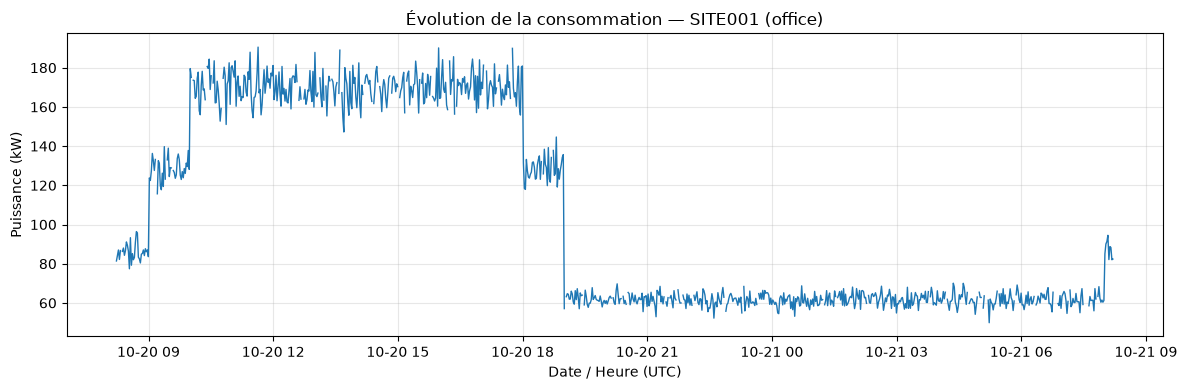

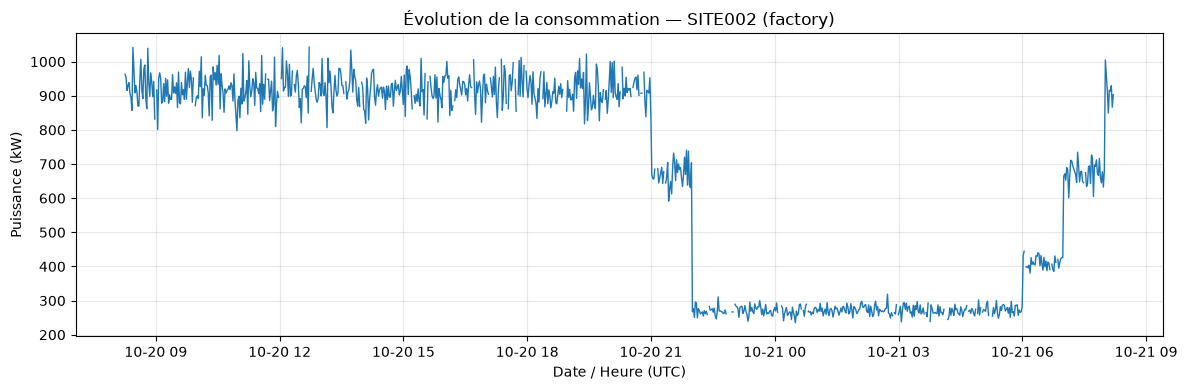

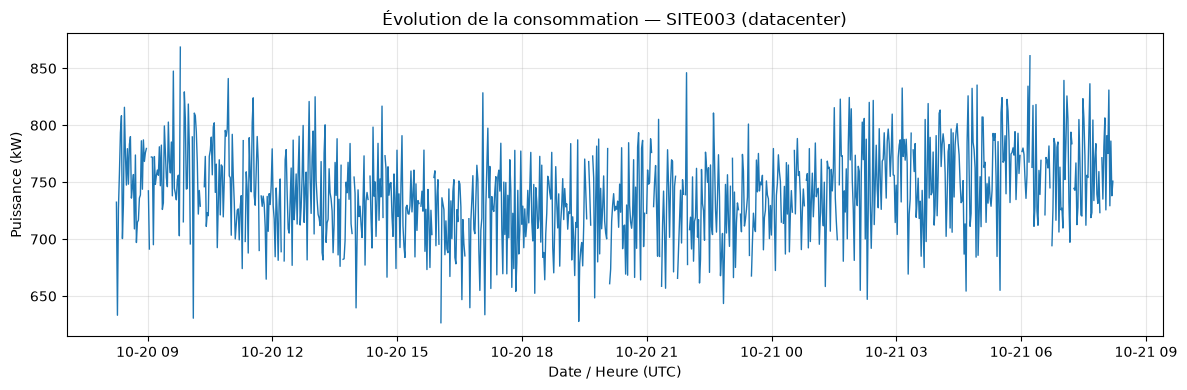

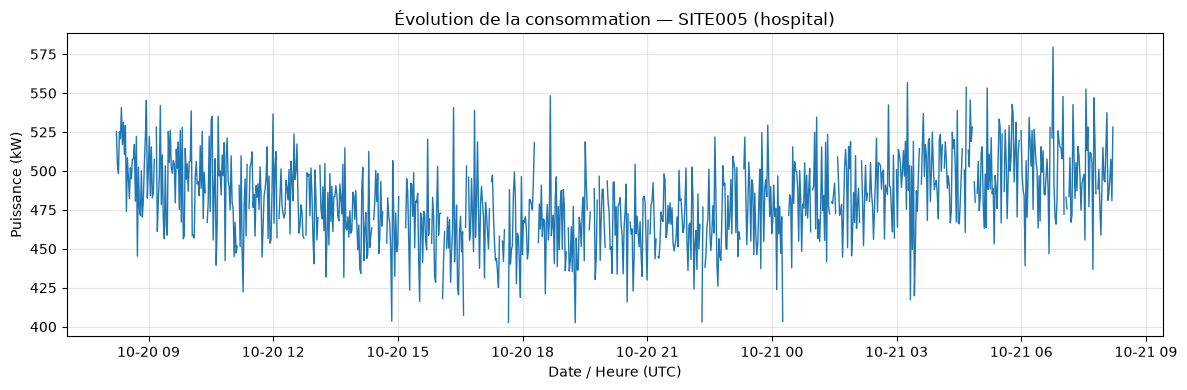

In [19]:
sites_to_plot = [
    "SITE001",  # Bureau
    "SITE002",  # Usine
    "SITE003",  # Datacenter
    "SITE005",  # Hôpital
]

for site_id in sites_to_plot:

    site_df = (
        df[df["site_id"] == site_id]
        .sort_values("timestamp")
    )

    site_type = site_df["site_type"].iloc[0]

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(
        site_df["timestamp"],
        site_df["consumption_kw"],
        linewidth=1,
    )

    ax.set_title(
        f"Évolution de la consommation — {site_id} ({site_type})"
    )

    ax.set_xlabel("Date / Heure (UTC)")
    ax.set_ylabel("Puissance (kW)")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

5 - Comparaison des profils horaires

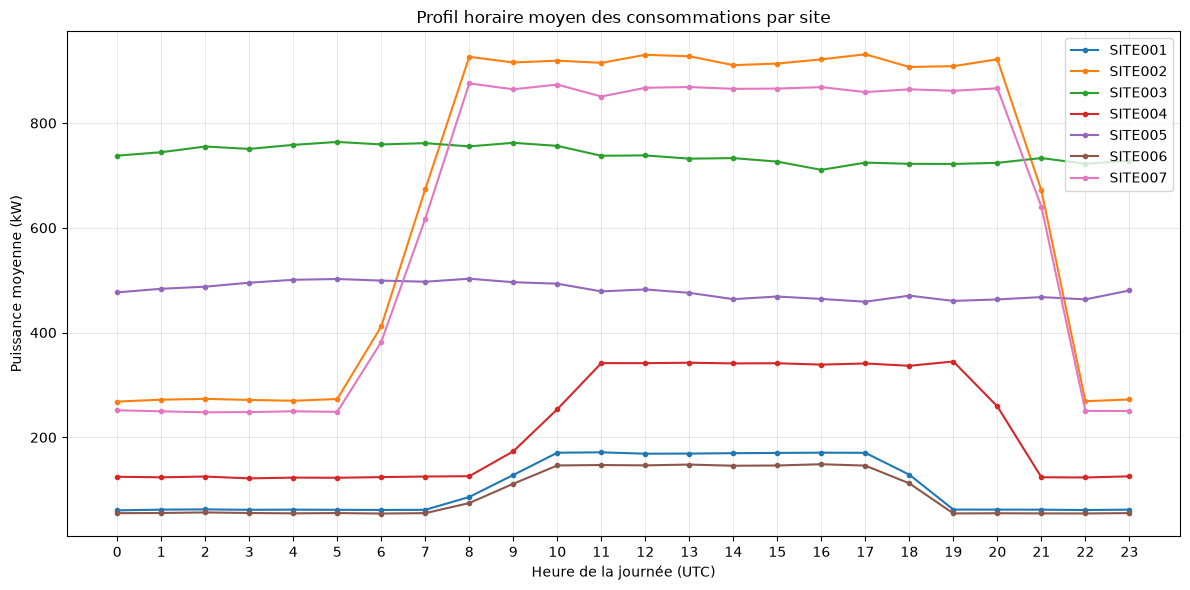

In [20]:
# Création d'une colonne horaire pour l'analyse
df["hour"] = df["timestamp"].dt.hour

hourly_consumption = (
    df.groupby(["site_id", "hour"])["consumption_kw"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

for site_id, group in hourly_consumption.groupby("site_id"):
    ax.plot(
        group["hour"],
        group["consumption_kw"],
        marker="o",
        markersize=3,
        label=site_id,
    )

ax.set_title("Profil horaire moyen des consommations par site")
ax.set_xlabel("Heure de la journée (UTC)")
ax.set_ylabel("Puissance moyenne (kW)")
ax.set_xticks(range(24))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusion — Analyse temporelle

L'analyse des 7 000 observations met en évidence une grille temporelle parfaitement régulière, avec un intervalle constant de 86,4 secondes entre les mesures.

Cette régularité, identique pour les sept sites, renforce l'hypothèse d'une génération synthétique des timestamps par l'API EnerVision.

L'étude des courbes de consommation révèle également des profils temporels distincts selon les catégories de bâtiments :

- Les bureaux et les usines présentent une forte variation entre les périodes d'activité et d'inactivité.
- Le commerce suit également un cycle journalier marqué.
- Le datacenter et l'hôpital présentent une consommation relativement stable, compatible avec une activité continue.

Les sites appartenant à une même catégorie semblent partager des profils horaires similaires, ce qui renforce l'intérêt d'une modélisation tenant compte du type de bâtiment.

**Hypothèse de modélisation :** les variables temporelles, notamment l'heure de la journée, associées au type de site, pourraient constituer des caractéristiques importantes pour la prédiction de consommation.

**Limites :** les données proviennent d'une API de simulation dont les valeurs peuvent varier entre deux requêtes identiques. Les observations couvrent une seule période de 24 heures et ne permettent pas de confirmer la répétabilité des cycles ni la capacité de généralisation des futurs modèles.